# **Tugas Akhir**   
### Analisis Perbandingan Model Deep Learning untuk Klasifikasi Emosi pada Teks Opini Publik Berbahasa Indonesia

2372023 - Eben Praus Yosia



---



# Part 3: Split Data

Membagi `data/clean.csv` menjadi train - validation - test secara stratified (proporsi kelas terjaga), lalu menyimpannya ke file yg terpisah.
- Train (70%): melatih model & membangun vocabulary / fit TF-IDF
- Validation (15%): memilih/mengevaluasi model selama pengembangan
- Test (15%): disimpan dan didiamkan dulu, waktu evaluasi final baru digunakan

In [1]:
import os
import json
import pandas as pd
from sklearn.model_selection import train_test_split

IN_PATH = "data/clean.csv"
OUT_DIR = "data"

TEXT_COL, LABEL_COL = "text", "label"
SEED = 42 # 1 seed tetap supaya split bisa diproduksi (cukup utk prototype)

df = pd.read_csv(IN_PATH)
print("Data bersih:", df.shape)
df.head(3)

Data bersih: (7031, 2)


,text,label
0,pagi2 udah di buat emosi :),anger
1,"kok stabilitas negara, memange 10 thn negara t...",anger
2,dah lah emosi mulu liat emyu,anger


### Step 1 - Stratified split

In [2]:
# Langkah 1: pisahkan 70% train dan 30% sisa (stratify = label)
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df[LABEL_COL], random_state=SEED)

# Langkah 2: sisa 30% dibagi dua sama besar -> 15% val + 15% test (stratify = label)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df[LABEL_COL], random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

ukuran = pd.DataFrame({
    "split": ["train", "val", "test", "TOTAL"],
    "jumlah": [len(train_df), len(val_df), len(test_df), len(df)],
})
ukuran["persen (%)"] = (ukuran["jumlah"] / len(df) * 100).round(2)
ukuran

,split,jumlah,persen (%)
0,train,4921,69.99
1,val,1055,15.00
2,test,1055,15.00
3,TOTAL,7031,100.00


### Step 2 - Bukti proporsi kelas terjaga

In [3]:
# Jumlah per kelas di tiap split
jumlah = pd.DataFrame({
    "train": train_df[LABEL_COL].value_counts(),
    "val":   val_df[LABEL_COL].value_counts(),
    "test":  test_df[LABEL_COL].value_counts(),
    "semua": df[LABEL_COL].value_counts(),
})
print("Jumlah per kelas:")
display(jumlah)

# Persentase per kelas di tiap split
persen = (jumlah / jumlah.sum() * 100).round(2)
print("\nPersentase per kelas (%):")
display(persen)

# Selisih terbesar proporsi tiap split terhadap proporsi data keseluruhan (dalam poin persen)
selisih = persen[["train", "val", "test"]].sub(persen["semua"], axis=0).abs().max()
print("\nSelisih proporsi maksimum terhadap data keseluruhan (poin persen):")
display(selisih.round(2).to_frame("selisih_maks"))

Jumlah per kelas:


,train,val,test,semua
label,,,,
neutral,1390,298,298,1986
joy,878,189,188,1255
anger,786,168,169,1123
sad,706,151,151,1008
fear,633,136,136,905
love,528,113,113,754



Persentase per kelas (%):


,train,val,test,semua
label,,,,
neutral,28.25,28.25,28.25,28.25
joy,17.84,17.91,17.82,17.85
anger,15.97,15.92,16.02,15.97
sad,14.35,14.31,14.31,14.34
fear,12.86,12.89,12.89,12.87
love,10.73,10.71,10.71,10.72



Selisih proporsi maksimum terhadap data keseluruhan (poin persen):


,selisih_maks
train,0.01
val,0.06
test,0.05


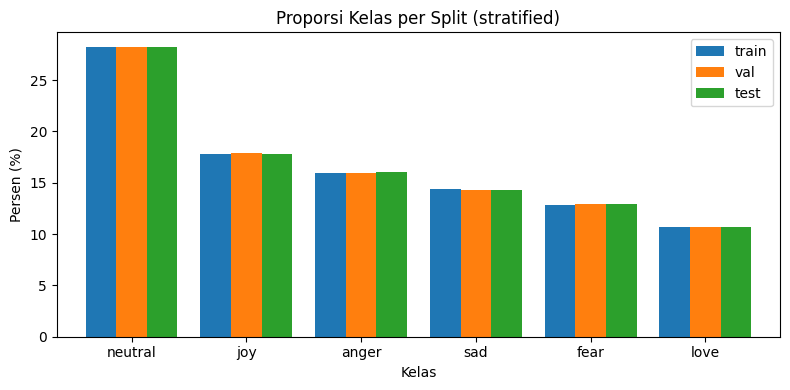

In [4]:
# Grafik sederhana: proporsi kelas per split (grafik batang harus tingginya hampir sama)
import matplotlib.pyplot as plt
os.makedirs("outputs/figures", exist_ok=True)

ax = persen[["train", "val", "test"]].plot(kind="bar", figsize=(8, 4), width=0.8)
ax.set_title("Proporsi Kelas per Split (stratified)")
ax.set_xlabel("Kelas"); ax.set_ylabel("Persen (%)")
plt.xticks(rotation=0); plt.tight_layout()
plt.savefig("outputs/figures/03_proporsi_kelas_per_split.png", dpi=150)
plt.show()

### Step 3 - Pengecekan kebocoran (leakage) antar split

In [5]:
# Teks di train / val / test tidak boleh saling tumpang tindih
s_train, s_val, s_test = set(train_df[TEXT_COL]), set(val_df[TEXT_COL]), set(test_df[TEXT_COL])
print("Irisan train & val :", len(s_train & s_val))
print("Irisan train & test:", len(s_train & s_test))
print("Irisan val & test  :", len(s_val & s_test))
assert not (s_train & s_val) and not (s_train & s_test) and not (s_val & s_test)
assert len(train_df) + len(val_df) + len(test_df) == len(df)
print("Lolos: tidak ada teks yang muncul di lebih dari satu split, dan tidak ada data yang hilang.")

Irisan train & val : 0
Irisan train & test: 0
Irisan val & test  : 0
Lolos: tidak ada teks yang muncul di lebih dari satu split, dan tidak ada data yang hilang.


### Step 4 - Simpan train, validation, dan test set

In [6]:
os.makedirs(OUT_DIR, exist_ok=True)
train_df.to_csv(f"{OUT_DIR}/train.csv", index=False)
val_df.to_csv(f"{OUT_DIR}/val.csv",     index=False)
test_df.to_csv(f"{OUT_DIR}/test.csv",   index=False)

# Pemetaan label -> angka (urut abjad, tetap) dipakai semua model di tahap berikutnya
label_map = {lab: i for i, lab in enumerate(sorted(df[LABEL_COL].unique()))}
with open(f"{OUT_DIR}/label_map.json", "w") as f:
    json.dump(label_map, f, indent=2)

print("Tersimpan di folder:", OUT_DIR)
print(" - train.csv", train_df.shape, "| val.csv", val_df.shape, "| test.csv", test_df.shape)
print(" - label_map.json:", label_map)

Tersimpan di folder: data
 - train.csv (4921, 2) | val.csv (1055, 2) | test.csv (1055, 2)
 - label_map.json: {'anger': 0, 'fear': 1, 'joy': 2, 'love': 3, 'neutral': 4, 'sad': 5}


### Notes Part 3:
- Ukuran train | val | test: 4.921 | 1.055 | 1.055
- Selisih proporsi kelas maksimum: 0,06 poin persen
- Irisan teks antar split: 0
- Test set tersimpan, belum dipakai untuk evaluasi apa pun